# T1.3 - Análise exploratória (EDA)

Diabetes 130-US hospitals (1999–2008). Objetivo do projeto: estimar, no momento da alta, o risco de readmissão em **menos de 30 dias**.

Este notebook **descreve e quantifica**. As decisões (exclusões, target, features, limpeza) são tomadas nas tarefas T1.4–T1.9 e registadas em `docs/decisions.md`.

Os dados são lidos com `src/data/load.py` (só `?` é missing; `"None"` em `A1Cresult`/`max_glu_serum` = teste não realizado) e os IDs descodificados com `src/data/mappings.py`. Só se mostram agregados, nunca linhas individuais.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency

from src.data.load import load_diabetic_data, validate_diabetic_data, describe_dtypes
from src.data.mappings import parse_ids_mapping, decode_ids

FIG_DIR = ROOT / "docs" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 60)

df = load_diabetic_data(ROOT / "data/raw/diabetic_data.csv")
validate_diabetic_data(df)
df = decode_ids(df, parse_ids_mapping(ROOT / "data/raw/IDS_mapping.csv"))
df["target"] = (df["readmitted"] == "<30").astype(int)  # só para exploração; definição formal em T1.5
BASE_RATE = df["target"].mean()
df.shape, round(BASE_RATE, 4)

((101766, 54), np.float64(0.1116))

In [2]:
def wilson(k, n, z=1.96):
    """Intervalo de confiança de Wilson (95%) para uma proporção."""
    p = k / n
    den = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / den
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / den
    return centre - half, centre + half


def rate_by(data, col, min_n=0, order=None):
    """Taxa de readmissão <30 por categoria, com n e IC 95%."""
    g = data.groupby(col, dropna=False, observed=True)["target"].agg(n="size", pos="sum")
    g = g[g["n"] >= min_n]
    g["rate"] = g["pos"] / g["n"]
    lo, hi = wilson(g["pos"], g["n"])
    g["ci_low"], g["ci_high"] = lo, hi
    g.index = g.index.astype("object").where(g.index.notna(), "(missing)")
    if order is not None:
        g = g.reindex([o for o in order if o in g.index])
    return g


def plot_rate(g, title, ax=None, label_n=True):
    """Barras horizontais com a taxa <30, IC 95% e linha da taxa global."""
    ax = ax or plt.subplots(figsize=(7, 0.35 * len(g) + 1.2))[1]
    y = np.arange(len(g))
    ax.barh(y, g["rate"], xerr=[g["rate"] - g["ci_low"], g["ci_high"] - g["rate"]],
            color="#3F63B5", alpha=0.85, error_kw=dict(ecolor="#555", lw=1))
    ax.set_yticks(y, [str(i) for i in g.index])
    ax.invert_yaxis()
    ax.axvline(BASE_RATE, color="#C4291C", ls="--", lw=1, label=f"global {BASE_RATE:.1%}")
    ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1, decimals=0))
    if label_n:
        for yi, (r, n) in enumerate(zip(g["ci_high"], g["n"])):
            ax.text(r + 0.003, yi, f"n={n:,}".replace(",", " "), va="center", fontsize=8, color="#555")
    ax.set_title(title, loc="left", fontsize=11)
    ax.set_xlabel("taxa de readmissão <30 dias")
    ax.legend(loc="best", fontsize=8)
    return ax

## 1. Visão geral e qualidade

In [3]:
dtypes = describe_dtypes(df.drop(columns="target"))
print(dtypes.value_counts().to_string())
print("encounter_id duplicados:", df["encounter_id"].duplicated().sum())
print("doentes únicos:", df["patient_nbr"].nunique())

dtype
str       34
int64     13
string     6
encounter_id duplicados: 0
doentes únicos: 71518


In [4]:
# As 23 colunas de medicamentos estão seguidas no ficheiro (de metformin a metformin-pioglitazone).
# Cada uma indica o que aconteceu ao fármaco no encontro: No (não prescrito), Steady (dose mantida),
# Up (dose aumentada) ou Down (dose reduzida). MED_COLS é reutilizada na secção 6.
MED_COLS = df.columns[df.columns.get_loc("metformin"): df.columns.get_loc("metformin-pioglitazone") + 1].tolist()

# Para todas as colunas (não só medicamentos): % de linhas ocupada pelo valor mais frequente.
# dropna=False conta o NaN como valor, para uma coluna quase toda em falta também aparecer.
top_share = {c: df[c].value_counts(normalize=True, dropna=False).iloc[0] for c in df.columns if c != "target"}
quasi = (pd.Series(top_share, name="valor_mais_frequente_%").mul(100).round(2)
         .sort_values(ascending=False))

# Colunas (quase) constantes: ≥99% das linhas com o mesmo valor quase não têm informação para o modelo.
quasi[quasi >= 99].to_frame()

,valor_mais_frequente_%
glimepiride-pioglitazone,100.00
metformin-pioglitazone,100.00
metformin-rosiglitazone,100.00
citoglipton,100.00
acetohexamide,100.00
troglitazone,100.00
examide,100.00
glipizide-metformin,99.99
tolbutamide,99.98
tolazamide,99.96


**Validação de `change` e `diabetesMed`.** Segundo a documentação, `change = "Ch"` indica uma alteração na medicação para a diabetes (dose ou fármaco) e `diabetesMed = "Yes"` que foi prescrito algum medicamento para a diabetes. Confirma-se isto com as 23 colunas de medicamentos?

In [5]:
n_active = df[MED_COLS].ne("No").sum(axis=1)               # nº de medicamentos prescritos no encontro
dose_change = df[MED_COLS].isin(["Up", "Down"]).any(axis=1)  # algum medicamento com dose alterada

# diabetesMed deve ser "Yes" sse há pelo menos um medicamento prescrito.
print("diabetesMed == (n_active >= 1):", ((df["diabetesMed"] == "Yes") == (n_active >= 1)).all())

# change vs medicamentos: nº de prescritos e se houve alteração de dose.
profile = pd.Series(np.select([n_active == 0, dose_change, n_active == 1],
                              ["0 medicamentos", "dose alterada (Up/Down)", "1 medicamento, Steady"],
                              "≥2 medicamentos, todos Steady"), index=df.index, name="perfil")
display(pd.crosstab(profile, df["change"], margins=True))

# Regra empírica: Ch sse houve alteração de dose OU há ≥2 medicamentos prescritos.
print("change == 'Ch' sse dose alterada ou n_active >= 2:",
      ((df["change"] == "Ch") == (dose_change | (n_active >= 2))).all())

diabetesMed == (n_active >= 1): True


change,Ch,No,All
perfil,,,
0 medicamentos,0,23403,23403
"1 medicamento, Steady",0,31352,31352
dose alterada (Up/Down),27703,0,27703
"≥2 medicamentos, todos Steady",19308,0,19308
All,47011,54755,101766


change == 'Ch' sse dose alterada ou n_active >= 2: True


In [6]:
# Testes à hipótese "os Ch com tudo Steady são trocas/adições de fármaco".

# 1) Combinações em dose fixa são 2 substâncias numa só coluna. Se Ch refletisse fármacos,
#    glyburide-metformin sozinho e Steady contaria como 2; se reflete colunas, conta como 1.
solo_combo = df["glyburide-metformin"].ne("No") & (n_active == 1) & ~dose_change
print("glyburide-metformin sozinho e Steady:", df.loc[solo_combo, "change"].value_counts().to_dict())

# 2) Doentes com encontro anterior (encounter_id como proxy da ordem temporal): o grupo
#    "≥2 Steady" mantém exatamente os mesmos fármacos que no encontro anterior?
d = df.sort_values(["patient_nbr", "encounter_id"])
active = d[MED_COLS].ne("No")
has_prev = d["patient_nbr"].eq(d["patient_nbr"].shift())
same_as_prev = active.eq(active.shift()).all(axis=1)
prev_profile = profile.loc[d.index].shift()
grp = has_prev & (profile.loc[d.index] == "≥2 medicamentos, todos Steady")
print("≥2 Steady com encontro anterior:", grp.sum(),
      "| mesmos fármacos e anterior também ≥2 Steady:",
      (grp & same_as_prev & (prev_profile == "≥2 medicamentos, todos Steady")).sum())

# 3) Sinal: Ch junta grupos com risco diferente?
rate_by(df.assign(perfil=profile), "perfil")[["n", "rate"]].assign(rate=lambda g: (100 * g["rate"]).round(2))

glyburide-metformin sozinho e Steady: {'No': 199}


≥2 Steady com encontro anterior: 4932 | mesmos fármacos e anterior também ≥2 Steady: 1221


,n,rate
perfil,,
0 medicamentos,23403,9.60
"1 medicamento, Steady",31352,11.33
dose alterada (Up/Down),27703,13.06
"≥2 medicamentos, todos Steady",19308,10.04


**Conclusão.** `diabetesMed` bate certo sempre: é `Yes` exatamente quando há pelo menos um medicamento prescrito.

`change` **não** é uma medida fiável de mudança de medicação. Todos os 27 703 encontros com `Up`/`Down` são `Ch`, mas 19 308 dos 47 011 `Ch` (41%) não têm nenhuma dose alterada: são encontros com ≥2 medicamentos, todos `Steady`. A regra **`Ch` ⇔ alguma dose alterada ou ≥2 colunas de medicamentos ativas** reproduz `change` sem exceções. A explicação "mudança de fármaco" (documentação: *dosage or generic name*) não se sustenta para esses 41%:

- **Exatidão a mais.** Nenhum dos 19 308 doentes com terapêutica múltipla estável aparece como `No`. Um evento clínico real não coincidiria a 100% com uma contagem de colunas.
- **Conta colunas, não substâncias.** `glyburide-metformin` sozinho e `Steady` (2 substâncias, 1 coluna) é sempre `No` (199/199).
- **Terapêutica igual ao encontro anterior.** 1 221 encontros "≥2 Steady" têm exatamente os mesmos fármacos do encontro anterior do mesmo doente, que também era "≥2 Steady", e mesmo assim são `Ch`.
- **Mistura grupos de risco opostos.** Dose alterada: 13,1% de readmissão <30. "≥2 Steady": 10,0%, abaixo de "1 Steady" (11,3%). A diferença `Ch` vs `No` (11,8% vs 10,6%) vem só do primeiro grupo.

Hipótese mais provável: `change` foi derivada por quem construiu o dataset a partir de registos de medicação (ex.: mais de um registo = mudança), e não registada clinicamente. **Não confirmado**; há limitações:

- `encounter_id` é só um proxy da ordem temporal.
- Não se sabe como é codificado um fármaco iniciado ou suspenso durante o encontro (um fármaco suspenso pode aparecer como `No`, e então a troca é invisível nas colunas).
- Os dados só têm 23 colunas de medicamentos.

Implicação para T1.8/T1.9: `change` e `diabetesMed` não trazem informação além das colunas de medicamentos. Descartá-las e usar features explícitas (nº de medicamentos prescritos, nº com dose alterada, `Up` e `Down` separados). Não descrever `Ch` no relatório como "a medicação mudou".

In [7]:
pd.DataFrame({"gender": df["gender"].value_counts(), }).T, df["race"].value_counts(dropna=False).to_frame("n")

(gender  Female   Male  Unknown/Invalid
 gender   54708  47055                3,
                      n
 race                  
 Caucasian        76099
 AfricanAmerican  19210
 NaN               2273
 Hispanic          2037
 Other             1506
 Asian              641)

**Conclusão.** 101 766 encontros, 71 518 doentes, sem `encounter_id` duplicados. `examide` e `citoglipton` são constantes; mais 13 medicamentos têm ≥99,3% num só valor (`No`) e são candidatos a sair em T1.9. `gender` tem 3 `Unknown/Invalid`, demasiado poucos para uma categoria própria.

## 1.1 Verificações de consistência

A §1 valida tipos, duplicados e as regras de `change`/`diabetesMed`. Aqui cruzam-se variáveis para encontrar registos **impossíveis ou improváveis** (ex.: um recém-nascido com 70 anos). As regras estão em `src/data/quality.py` (testadas em `tests/test_quality.py`), organizadas em três camadas:

- **A** - coerência dentro do encontro (idade × tipo de admissão, sexo × diagnóstico, estrutura dos diagnósticos);
- **B** - formato e domínio dos valores;
- **C** - coerência do mesmo doente entre encontros (ordem por `encounter_id`, P17).

Severidade: `erro` = impossível; `suspeito` = improvável mas explicável; `limitacao` = esperado pela construção do dataset. Esta secção **só conta**: o `df` não é alterado e as ações ficam propostas em `docs/decisions.md` (D2-D4).

In [8]:
from src.data.quality import run_checks, check_masks, age_lower

ids_mapping = parse_ids_mapping(ROOT / "data/raw/IDS_mapping.csv")
checks = run_checks(df, ids_mapping)
masks = check_masks(df, ids_mapping)

any_error = masks[checks.index[checks["severidade"] == "erro"]].any(axis=1)
print(f"encontros com pelo menos um erro: {any_error.sum()} "
      f"({df.loc[any_error, 'patient_nbr'].nunique()} doentes, {any_error.mean():.3%})")
checks

encontros com pelo menos um erro: 59 (54 doentes, 0.058%)


,camada,descricao,severidade,n,%
id,,,,,
A1,A,Admissão Newborn (tipo 4) com idade >= 10,erro,9,0.009
A2,A,"Origem parto/nascimento (11-14, 23, 24) com id...",erro,5,0.005
A3,A,Alta de neonato (destino 10) com idade >= 10,erro,6,0.006
A4,A,Especialidade pediátrica com idade >= 20,suspeito,151,0.148
A5,A,Obstetrícia/ginecologia ou gravidez (630-679) ...,erro,0,0.000
A6,A,Gravidez (630-679) com idade >= 60,erro,0,0.000
A7,A,"Próstata (185, 600-602) em mulheres",erro,0,0.000
A8,A,diag_1 em falta com diag_2/diag_3 preenchidos,suspeito,20,0.020
A9,A,Mesmo código repetido em diag_1-3,suspeito,5492,5.397


**Detalhe das regras com violações** (só agregados). Idade dos encontros com admissão, origem ou alta típicas de recém-nascido (A1-A3), e o que acontece nos encontros posteriores a um óbito (C5).

In [9]:
neonatal = masks[["A1", "A2", "A3"]].any(axis=1)
display(pd.crosstab(df.loc[neonatal, "age"], "n").T)

print("C5 - readmitted nos encontros depois de um óbito:",
      df.loc[masks["C5"], "readmitted"].value_counts().to_dict())
print("C2 - doentes com mais de uma race:", df.loc[masks["C2"], "patient_nbr"].nunique(),
      "| C1 - com mais de um gender:", df.loc[masks["C1"], "patient_nbr"].nunique())

# B1: os códigos mal formados são números com os zeros à esquerda perdidos (008 -> 8)?
diag = df[["diag_1", "diag_2", "diag_3"]].stack()
malformed = diag[~diag.str.match(r"^(\d{3}(\.\d{1,2})?|V\d{2}(\.\d{1,2})?|E\d{3}(\.\d)?)$")]
print("B1 - códigos mal formados:", malformed.size, "| todos numéricos < 100:",
      bool((pd.to_numeric(malformed, errors="coerce") < 100).all()))

# A9: em que par de colunas está o código repetido?
d1, d2, d3 = (df[c] for c in ["diag_1", "diag_2", "diag_3"])
print("A9 - repetidos diag_1=diag_2:", int((d1 == d2).sum()), "| diag_1=diag_3:", int((d1 == d3).sum()),
      "| diag_2=diag_3:", int((d2 == d3).sum()))
print("A9 - % de códigos repetidos sem casas decimais:",
      round(100 * (~d2[d2 == d3].str.contains(r'\.')).mean(), 1))

age,[20-30),[40-50),[50-60),[60-70),[70-80),[80-90),[90-100)
col_0,,,,,,,
n,1,1,2,4,7,3,1


C5 - readmitted nos encontros depois de um óbito: {'<30': 9, '>30': 5}
C2 - doentes com mais de uma race: 123 | C1 - com mais de um gender: 3


B1 - códigos mal formados: 5732 | todos numéricos < 100: True
A9 - repetidos diag_1=diag_2: 1792 | diag_1=diag_3: 1411 | diag_2=diag_3: 2487
A9 - % de códigos repetidos sem casas decimais: 100.0


**Conclusão.** A qualidade geral é boa: **59 encontros (54 doentes, 0,06%) têm pelo menos um erro**, e os domínios (B2), duplicados (B3) e regras de sexo/idade nos diagnósticos (A5-A7, A10) estão limpos. Mas há registos impossíveis, que confirmam que o dataset tem erros de introdução ou de ligação de registos.

- **A - dentro do encontro.** Todos os encontros com admissão, origem ou alta de recém-nascido (A1-A3, 19 encontros) são de doentes com 20 a 100 anos: nenhum é um recém-nascido. São códigos mal atribuídos (provavelmente o ID errado), não bebés com diabetes. A4 (151 adultos em especialidades pediátricas) é plausível em parte (jovens adultos com doença crónica, cirurgia pediátrica) e fica como suspeito. A9: os 5 492 códigos repetidos não têm casas decimais. A hipótese é que os códigos foram truncados aos 3 dígitos (ex.: 276.1 e 276.8 -> 276), o que perde informação mas não é um erro clínico.
- **B - formato.** Os 5 732 códigos "mal formados" (5 567 encontros) são todos códigos numéricos < 100 que perderam os zeros à esquerda (008 -> `8`). Não afeta a conversão numérica do `icd9_group` (§8), mas afeta qualquer agrupamento por texto (prefixo). B4 (62,6% sem 250.xx em `diag_1-3`) é uma **limitação**: o critério de inclusão usa todos os diagnósticos e o dataset só guarda 3.
- **C - entre encontros.** 14 encontros acontecem **depois de um óbito** do mesmo doente (C5) e 18 têm idade **mais baixa** que o encontro anterior (C3). Isto significa que ou o `patient_nbr` junta pessoas diferentes ou o `encounter_id` não é ordem temporal (põe em causa P17, ver `docs/decisions.md`). 123 doentes têm mais de uma `race` (C2), o que é plausível em dados autorreportados. 490 encontros `NO` têm encontro seguinte (C6): a readmissão pode ter ocorrido depois da janela de observação do `readmitted`, ou o rótulo está errado; fica por decidir. C7 (3 224 `<30` no último encontro) é esperado: a readmissão pode não cumprir os critérios de inclusão do dataset.

Ações propostas (sem aplicar aqui): excluir os encontros com `erro` (D2), harmonizar a `race` por doente (D3), repor os zeros à esquerda nos códigos ICD-9 (D4).

## 2. Target

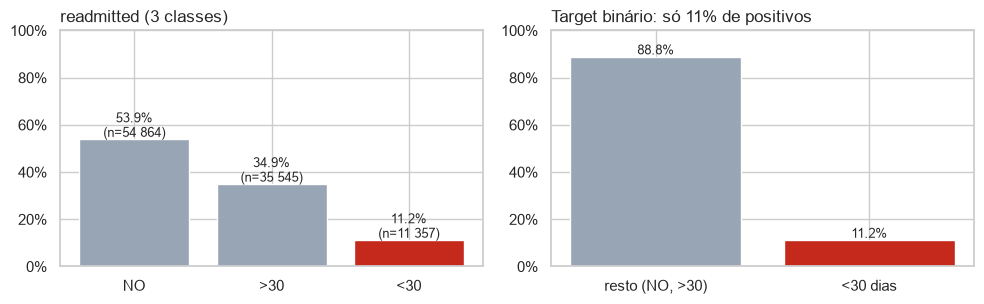

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
order = ["NO", ">30", "<30"]
vc = df["readmitted"].value_counts().reindex(order)
axes[0].bar(order, vc / len(df), color=["#98A5B4", "#98A5B4", "#C4291C"])
for i, v in enumerate(vc):
    axes[0].text(i, v / len(df) + 0.01, f"{v/len(df):.1%}\n(n={v:,})".replace(",", " "), ha="center", fontsize=9)
axes[0].set_title("readmitted (3 classes)", loc="left")
bin_vc = df["target"].value_counts().sort_index()
axes[1].bar(["resto (NO, >30)", "<30 dias"], bin_vc / len(df), color=["#98A5B4", "#C4291C"])
for i, v in enumerate(bin_vc):
    axes[1].text(i, v / len(df) + 0.01, f"{v/len(df):.1%}", ha="center", fontsize=9)
axes[1].set_title("Target binário: só 11% de positivos", loc="left")
for ax in axes:
    ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1, decimals=0)); ax.set_ylim(0, 1)
plt.tight_layout(); fig.savefig(FIG_DIR / "01_target.png", dpi=150, bbox_inches="tight"); plt.show()

**Conclusão.** 11,16% de positivos (<30 dias). O desequilíbrio é forte: um modelo que preveja sempre "não" tem 88,8% de accuracy. Usar PR-AUC e recall@k (T3.2) e tratar o desequilíbrio em T3.1.

## 3. Missing por campo

Distinguem-se duas coisas: **missing** (`?` no ficheiro) e **não medido** (`"None"` em `A1Cresult` e `max_glu_serum`, que é informação clínica válida).

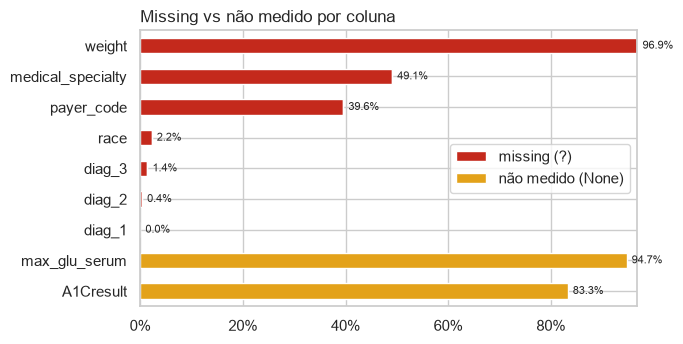

,missing (?),não medido (None)
weight,96.86,0.00
medical_specialty,49.08,0.00
payer_code,39.56,0.00
race,2.23,0.00
diag_3,1.40,0.00
diag_2,0.35,0.00
diag_1,0.02,0.00
max_glu_serum,0.00,94.75
A1Cresult,0.00,83.28


In [11]:
miss = df.drop(columns="target").isna().mean()
not_measured = pd.Series({c: (df[c] == "None").mean() for c in ["A1Cresult", "max_glu_serum"]})
tab = (pd.DataFrame({"missing (?)": miss, "não medido (None)": not_measured}).fillna(0)
       .query("`missing (?)` > 0 or `não medido (None)` > 0")
       .sort_values(["missing (?)", "não medido (None)"], ascending=False))
fig, ax = plt.subplots(figsize=(7, 3.6))
tab.plot.barh(stacked=True, ax=ax, color=["#C4291C", "#E3A21A"])
ax.invert_yaxis(); ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1, decimals=0))
ax.set_title("Missing vs não medido por coluna", loc="left")
for i, (m, nm) in enumerate(tab.values):
    ax.text(m + nm + 0.01, i, f"{m+nm:.1%}", va="center", fontsize=8)
plt.tight_layout(); fig.savefig(FIG_DIR / "02_missing.png", dpi=150, bbox_inches="tight"); plt.show()
(tab * 100).round(2)

O facto de faltar um valor está associado ao target? Taxa de `<30` com e sem o valor presente:

In [12]:
rows = []
for c in ["weight", "payer_code", "medical_specialty", "race"]:
    g = rate_by(df.assign(_present=df[c].notna().map({True: "presente", False: "missing"})), "_present")
    for k, r in g.iterrows():
        rows.append({"coluna": c, "valor": k, "n": r["n"], "taxa_<30_%": round(100 * r["rate"], 2),
                     "IC95%": f"{100*r['ci_low']:.1f}–{100*r['ci_high']:.1f}"})
for c in ["A1Cresult", "max_glu_serum"]:
    g = rate_by(df.assign(_m=(df[c] == "None").map({True: "não medido", False: "medido"})), "_m")
    for k, r in g.iterrows():
        rows.append({"coluna": c, "valor": k, "n": r["n"], "taxa_<30_%": round(100 * r["rate"], 2),
                     "IC95%": f"{100*r['ci_low']:.1f}–{100*r['ci_high']:.1f}"})
pd.DataFrame(rows).set_index(["coluna", "valor"])

n  taxa_<30_%      IC95%
coluna            valor                                     
weight            missing     98569.0       11.16  11.0–11.4
                  presente     3197.0       11.17  10.1–12.3
payer_code        missing     40256.0       11.49  11.2–11.8
                  presente    61510.0       10.94  10.7–11.2
medical_specialty missing     49949.0       11.57  11.3–11.9
                  presente    51817.0       10.76  10.5–11.0
race              missing      2273.0        8.27    7.2–9.5
                  presente    99493.0       11.23  11.0–11.4
A1Cresult         medido      17018.0        9.85   9.4–10.3
                  não medido  84748.0       11.42  11.2–11.6
max_glu_serum     medido       5346.0       12.36  11.5–13.3
                  não medido  96420.0       11.09  10.9–11.3

**Conclusão.** `weight` tem 96,9% de missing e a taxa de <30 é igual com e sem peso (11,2% vs 11,2%): **descartar**, nem o indicador ajuda. `medical_specialty` (49,1%) e `payer_code` (39,6%) têm missing ligeiramente informativo (≈0,5–0,8 p.p.); se ficarem, `?` entra como categoria própria. `race` em falta tem taxa mais baixa (8,3%). `A1Cresult` e `max_glu_serum` não têm missing: "None" é **não medido** e tem taxas diferentes (A1C não medido 11,4% vs medido 9,9%), por isso é informação a manter como categoria.

## 4. Encontros por doente

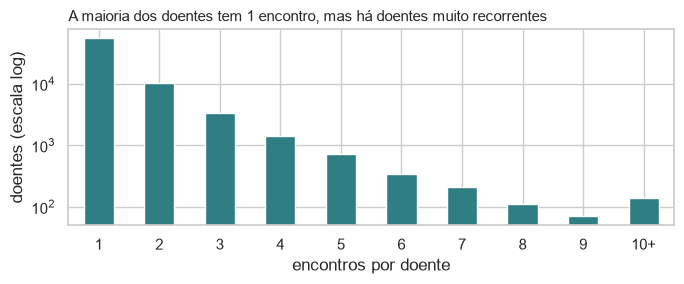

,valor
doentes,71518.0
doentes com >1 encontro (%),23.5
encontros de doentes recorrentes (%),46.2
máximo de encontros num doente,40.0


In [13]:
enc = df.groupby("patient_nbr").size()
summary = pd.Series({
    "doentes": len(enc),
    "doentes com >1 encontro (%)": round(100 * (enc > 1).mean(), 1),
    "encontros de doentes recorrentes (%)": round(100 * enc[enc > 1].sum() / len(df), 1),
    "máximo de encontros num doente": enc.max(),
})
fig, ax = plt.subplots(figsize=(7, 3))
enc.clip(upper=10).value_counts().sort_index().plot.bar(ax=ax, color="#2F7E83")
ax.set_xticklabels([str(i) if i < 10 else "10+" for i in range(1, 11)], rotation=0)
ax.set_yscale("log"); ax.set_xlabel("encontros por doente"); ax.set_ylabel("doentes (escala log)")
ax.set_title("A maioria dos doentes tem 1 encontro, mas há doentes muito recorrentes", loc="left", fontsize=11)
plt.tight_layout(); fig.savefig(FIG_DIR / "03_encontros_por_doente.png", dpi=150, bbox_inches="tight"); plt.show()
summary.to_frame("valor")

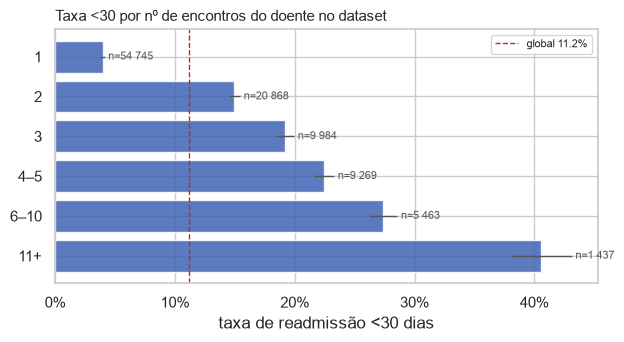

In [14]:
df["_n_enc_doente"] = df["patient_nbr"].map(enc)
bins = pd.cut(df["_n_enc_doente"], [0, 1, 2, 3, 5, 10, 100], labels=["1", "2", "3", "4–5", "6–10", "11+"])
plot_rate(rate_by(df.assign(_b=bins), "_b"), "Taxa <30 por nº de encontros do doente no dataset")
plt.show()

**Conclusão.** 23,5% dos doentes têm mais de 1 encontro e representam 46,2% dos encontros, o que obriga a um split agrupado por `patient_nbr` (T1.7). A taxa de <30 sobe de 4,0% (doentes com 1 encontro) para 23,2% (3 ou mais). **Atenção:** isto é em grande parte fuga de informação, porque uma readmissão gera ela própria um novo encontro no dataset. O nº de encontros no dataset **não pode** ser feature.

## 5. População elegível (pré-visualização de T1.4)

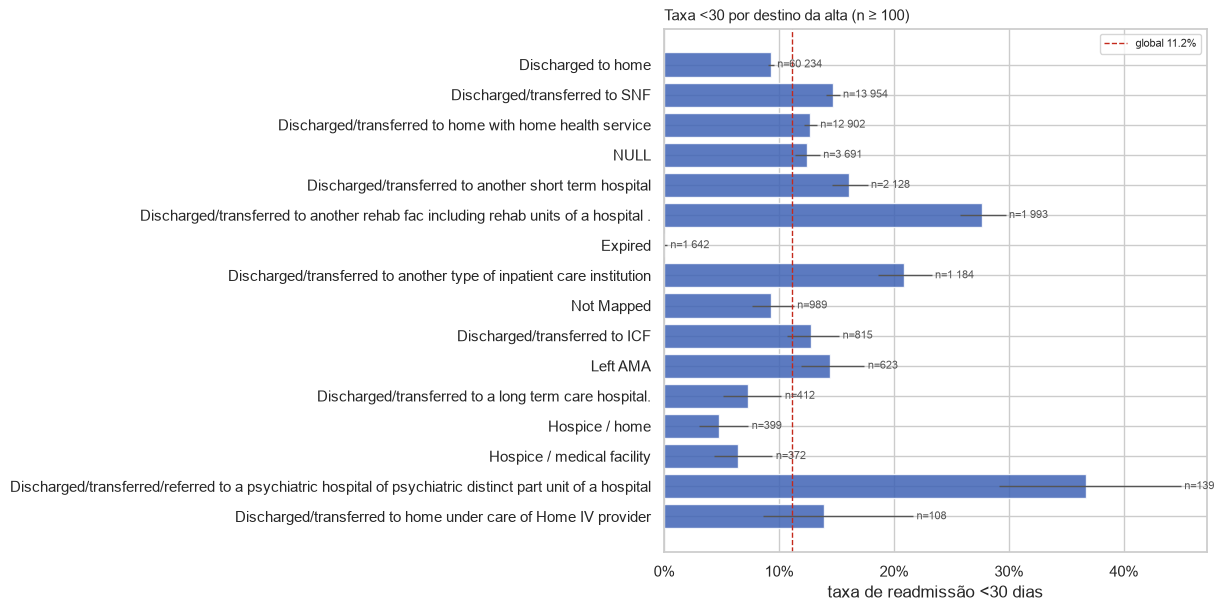

,,n,pos
discharge_disposition_id,discharge_disposition_id_desc,,
11,Expired,1642,0
13,Hospice / home,399,19
14,Hospice / medical facility,372,24
19,"Expired at home. Medicaid only, hospice.",8,0
20,"Expired in a medical facility. Medicaid only, hospice.",2,0


In [15]:
DEAD_HOSPICE = [11, 13, 14, 19, 20, 21]
g = rate_by(df, "discharge_disposition_id_desc").sort_values("n", ascending=False)
plot_rate(g[g["n"] >= 100], "Taxa <30 por destino da alta (n ≥ 100)")
plt.show()
dh = df["discharge_disposition_id"].isin(DEAD_HOSPICE)
df[dh].groupby(["discharge_disposition_id", "discharge_disposition_id_desc"]).agg(n=("target", "size"), pos=("target", "sum"))

In [16]:
pd.DataFrame({
    "n": [len(df), (~dh).sum()],
    "taxa_<30_%": [round(100 * df["target"].mean(), 2), round(100 * df.loc[~dh, "target"].mean(), 2)],
    "doentes": [df["patient_nbr"].nunique(), df.loc[~dh, "patient_nbr"].nunique()],
}, index=["todos", "sem óbito/hospício"])

,n,taxa_<30_%,doentes
todos,101766,11.16,71518
sem óbito/hospício,99343,11.39,69990


**Conclusão.** As 6 categorias de óbito/hospício somam 2 423 encontros (o código 21 não aparece). Os óbitos (11, 19, 20) têm 0 readmissões e os hospícios (13, 14) só 43 no total. Excluí-los deixa 99 343 encontros, 69 990 doentes e sobe a taxa de positivos para 11,39%. Destino da alta varia muito: casa 9,3%, SNF 14,7%, reabilitação 27,7%. Decisão em T1.4.

## 6. Análise univariada

In [17]:
NUM_COLS = ["time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications",
            "number_outpatient", "number_emergency", "number_inpatient", "number_diagnoses"]
desc = df[NUM_COLS].describe(percentiles=[.5, .95, .99]).T
desc["skew"] = df[NUM_COLS].skew()
desc["% zeros"] = (df[NUM_COLS] == 0).mean() * 100
desc.round(2)

,count,mean,std,min,50%,95%,99%,max,skew,% zeros
time_in_hospital,101766.0,4.40,2.99,1.0,4.0,11.0,14.0,14.0,1.13,0.00
num_lab_procedures,101766.0,43.10,19.67,1.0,44.0,73.0,85.0,132.0,-0.24,0.00
num_procedures,101766.0,1.34,1.71,0.0,1.0,5.0,6.0,6.0,1.32,45.84
num_medications,101766.0,16.02,8.13,1.0,15.0,31.0,43.0,81.0,1.33,0.00
number_outpatient,101766.0,0.37,1.27,0.0,0.0,2.0,5.0,42.0,8.83,83.55
number_emergency,101766.0,0.20,0.93,0.0,0.0,1.0,3.0,76.0,22.86,88.81
number_inpatient,101766.0,0.64,1.26,0.0,0.0,3.0,6.0,21.0,3.61,66.46
number_diagnoses,101766.0,7.42,1.93,1.0,8.0,9.0,9.0,16.0,-0.88,0.00


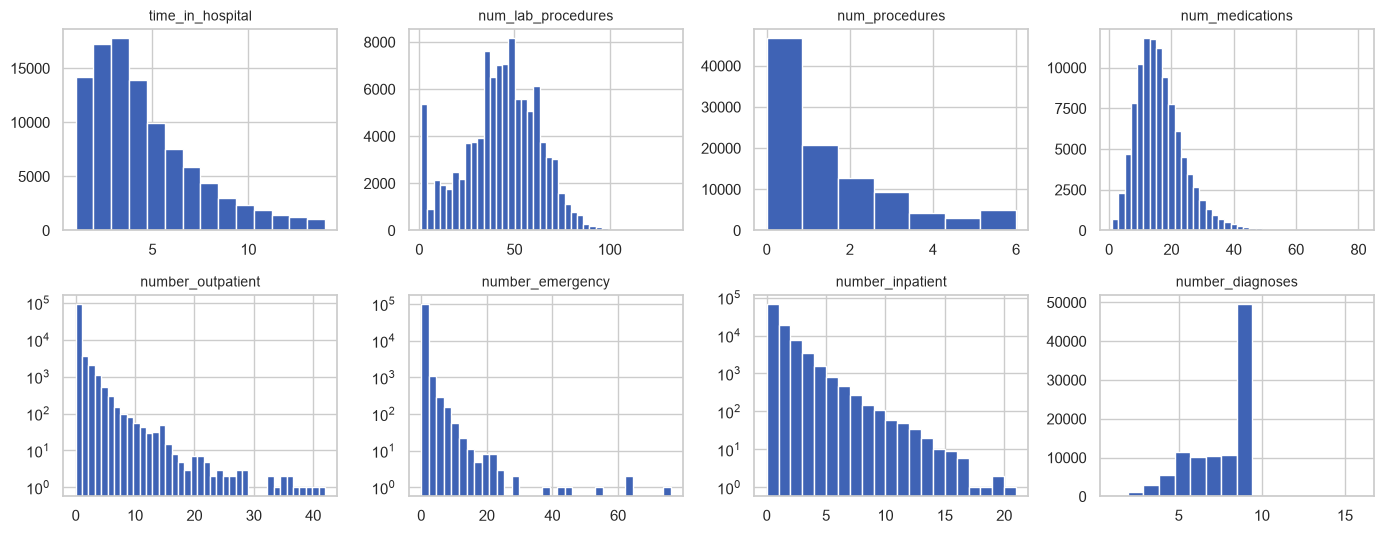

In [18]:
fig, axes = plt.subplots(2, 4, figsize=(14, 5.5))
for ax, c in zip(axes.flat, NUM_COLS):
    ax.hist(df[c], bins=min(40, df[c].nunique()), color="#3F63B5")
    ax.set_title(c, fontsize=10)
    if df[c].skew() > 3:
        ax.set_yscale("log")
plt.tight_layout(); plt.show()

A tabela resume as 8 numéricas (percentis, `skew` e % de zeros) e os histogramas mostram a forma de cada uma; o eixo y está em escala log quando skew > 3 (`number_outpatient`, `number_emergency`, `number_inpatient`). Há dois tipos de variável:

- **Contagens de visitas no ano anterior.** São sobretudo "zero ou não zero" (66–89% de zeros), com caudas longas. Ex.: `number_emergency` tem p99 = 3 e máximo 76, por isso média e desvio padrão são pouco representativos.
- **Medidas do próprio encontro** (`time_in_hospital`, `num_lab_procedures`, `num_medications`). Têm distribuições mais regulares.

Três variáveis têm **limites que parecem vir do registo e não da clínica**:

- `time_in_hospital` vai de 1 a 14 dias. É um critério de inclusão do dataset: internamentos mais longos não entram.
- `num_procedures` para em 6 (4 954 encontros nesse valor). Provavelmente 6 = "6 ou mais".
- `number_diagnoses` acumula-se em 9 (48,6% dos encontros) e só 115 passam de 9. É coerente com um sistema que durante grande parte do período só guardava até 9 diagnósticos, e então 9 = "9 ou mais".

O limite de `time_in_hospital` está na documentação da UCI; os de `num_procedures` e `number_diagnoses` são inferidos dos dados.

In [19]:
CAT_COLS = ["age", "gender", "race", "admission_type_id_desc", "admission_source_id_desc",
            "change", "diabetesMed", "insulin", "A1Cresult", "max_glu_serum"]
for c in CAT_COLS:
    vc = df[c].value_counts(dropna=False)
    print(f"\n{c} ({vc.size} níveis):", (vc / len(df) * 100).round(1).head(8).to_dict())


age (10 níveis): {'[70-80)': 25.6, '[60-70)': 22.1, '[50-60)': 17.0, '[80-90)': 16.9, '[40-50)': 9.5, '[30-40)': 3.7, '[90-100)': 2.7, '[20-30)': 1.6}

gender (3 níveis): {'Female': 53.8, 'Male': 46.2, 'Unknown/Invalid': 0.0}

race (6 níveis): {'Caucasian': 74.8, 'AfricanAmerican': 18.9, nan: 2.2, 'Hispanic': 2.0, 'Other': 1.5, 'Asian': 0.6}

admission_type_id_desc (8 níveis): {'Emergency': 53.1, 'Elective': 18.5, 'Urgent': 18.2, 'NULL': 5.2, 'Not Available': 4.7, 'Not Mapped': 0.3, 'Trauma Center': 0.0, 'Newborn': 0.0}

admission_source_id_desc (17 níveis): {'Emergency Room': 56.5, 'Physician Referral': 29.1, 'NULL': 6.7, 'Transfer from a hospital': 3.1, 'Transfer from another health care facility': 2.2, 'Clinic Referral': 1.1, 'Transfer from a Skilled Nursing Facility (SNF)': 0.8, 'HMO Referral': 0.2}

change (2 níveis): {'No': 53.8, 'Ch': 46.2}

diabetesMed (2 níveis): {'Yes': 77.0, 'No': 23.0}

insulin (4 níveis): {'No': 46.6, 'Steady': 30.3, 'Down': 12.0, 'Up': 11.1}

A1Cresult (

In [20]:
spec = df["medical_specialty"].fillna("(missing)").value_counts()
print("níveis:", spec.size, "| níveis com <100 encontros:", (spec < 100).sum())
spec.head(15).to_frame("n")

níveis: 73 | níveis com <100 encontros: 44


,n
medical_specialty,
(missing),49949
InternalMedicine,14635
Emergency/Trauma,7565
Family/GeneralPractice,7440
Cardiology,5352
Surgery-General,3099
Nephrology,1613
Orthopedics,1400
Orthopedics-Reconstructive,1233


In [21]:
med = pd.DataFrame({c: df[c].value_counts(normalize=True) for c in MED_COLS}).T.fillna(0).mul(100).round(2)
med[["No", "Steady", "Up", "Down"]].sort_values("No")

,No,Steady,Up,Down
insulin,46.56,30.31,11.12,12.01
metformin,80.36,18.03,1.05,0.57
glipizide,87.53,11.16,0.76,0.55
glyburide,89.53,9.11,0.80,0.55
pioglitazone,92.80,6.85,0.23,0.12
rosiglitazone,93.75,5.99,0.17,0.09
glimepiride,94.90,4.59,0.32,0.19
repaglinide,98.49,1.36,0.11,0.04
glyburide-metformin,99.31,0.68,0.01,0.01
nateglinide,99.31,0.66,0.02,0.01


**Conclusão.** `number_outpatient`, `number_emergency` e `number_inpatient` são muito assimétricas (skew 3,6–22,9; 66–89% de zeros, com máximos de 42, 76 e 21): considerar log1p ou truncar no p99 para modelos lineares. `medical_specialty` tem 73 níveis, 44 com menos de 100 encontros: agrupar os raros. `admission_type` e `admission_source` têm categorias "NULL"/"Not Available"/"Not Mapped" que são, na prática, missing (≈10%).

## 7. Relação com o target

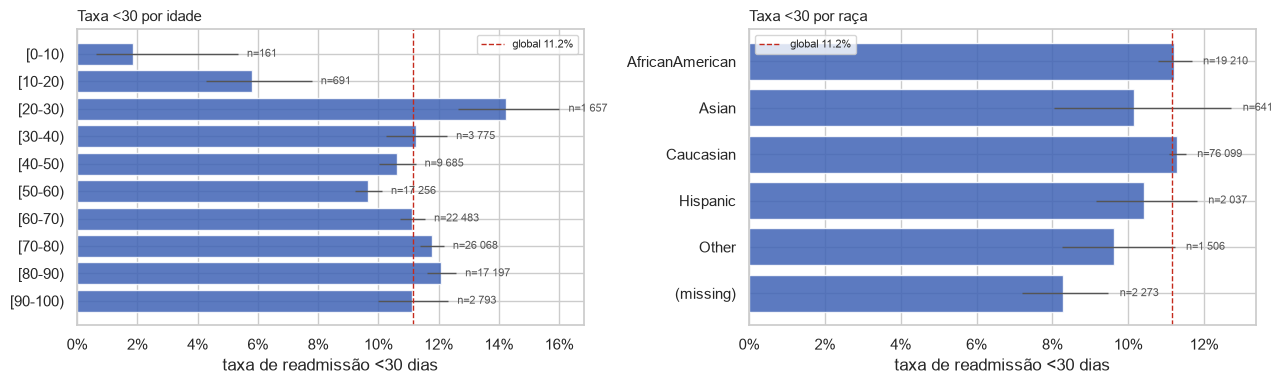

In [22]:
AGE_ORDER = sorted(df["age"].dropna().unique(), key=lambda s: int(s.strip("[").split("-")[0]))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
plot_rate(rate_by(df, "age", order=AGE_ORDER), "Taxa <30 por idade", ax=axes[0])
plot_rate(rate_by(df, "race"), "Taxa <30 por raça", ax=axes[1])
plt.tight_layout(); fig.savefig(FIG_DIR / "04_taxa_idade_raca.png", dpi=150, bbox_inches="tight"); plt.show()

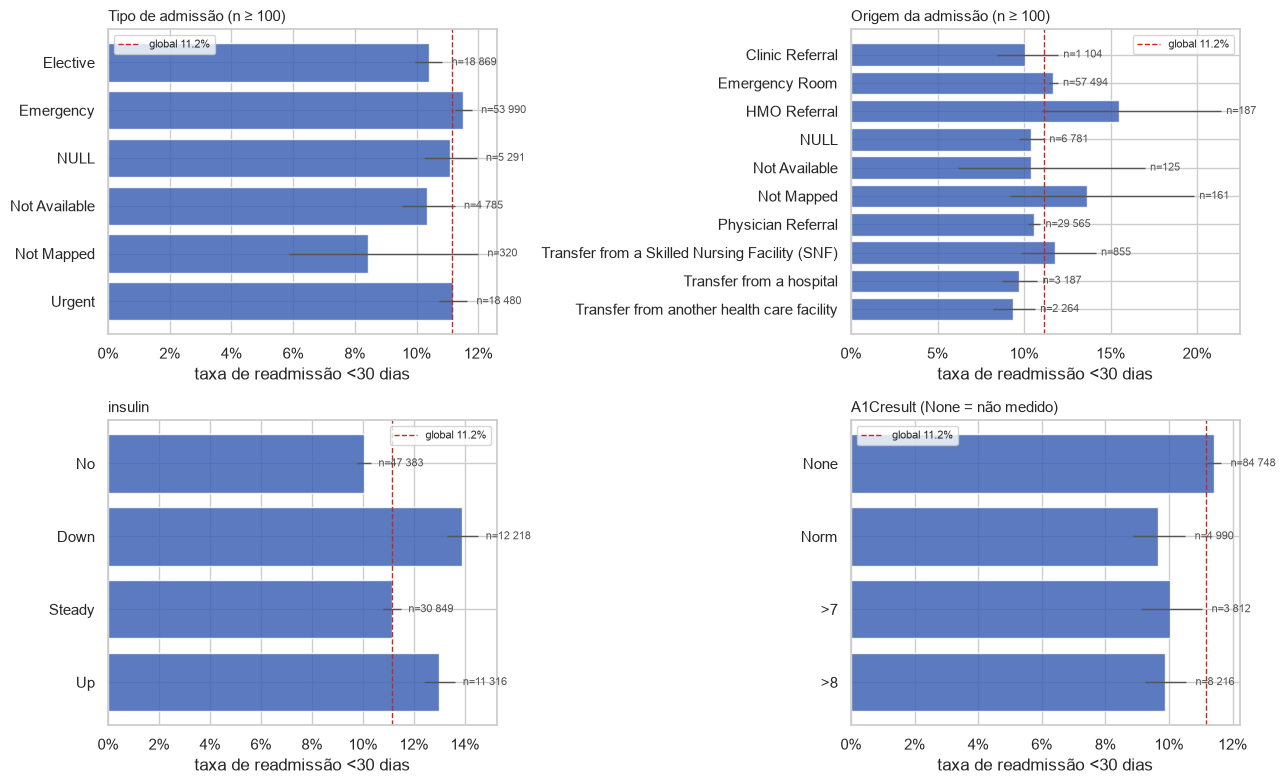

In [23]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
plot_rate(rate_by(df, "admission_type_id_desc", min_n=100), "Tipo de admissão (n ≥ 100)", ax=axes[0, 0])
plot_rate(rate_by(df, "admission_source_id_desc", min_n=100), "Origem da admissão (n ≥ 100)", ax=axes[0, 1])
plot_rate(rate_by(df, "insulin", order=["No", "Down", "Steady", "Up"]), "insulin", ax=axes[1, 0])
plot_rate(rate_by(df, "A1Cresult", order=["None", "Norm", ">7", ">8"]), "A1Cresult (None = não medido)", ax=axes[1, 1])
plt.tight_layout(); plt.show()

In [24]:
small = ["gender", "change", "diabetesMed", "max_glu_serum"]
pd.concat({c: rate_by(df, c)[["n", "rate"]] for c in small}).assign(rate=lambda d: (100 * d["rate"]).round(2))

n   rate
gender        Female           54708  11.25
              Male             47055  11.06
              Unknown/Invalid      3   0.00
change        Ch               47011  11.82
              No               54755  10.59
diabetesMed   No               23403   9.60
              Yes              78363  11.63
max_glu_serum >200              1485  12.46
              >300              1264  14.32
              None             96420  11.09
              Norm              2597  11.36

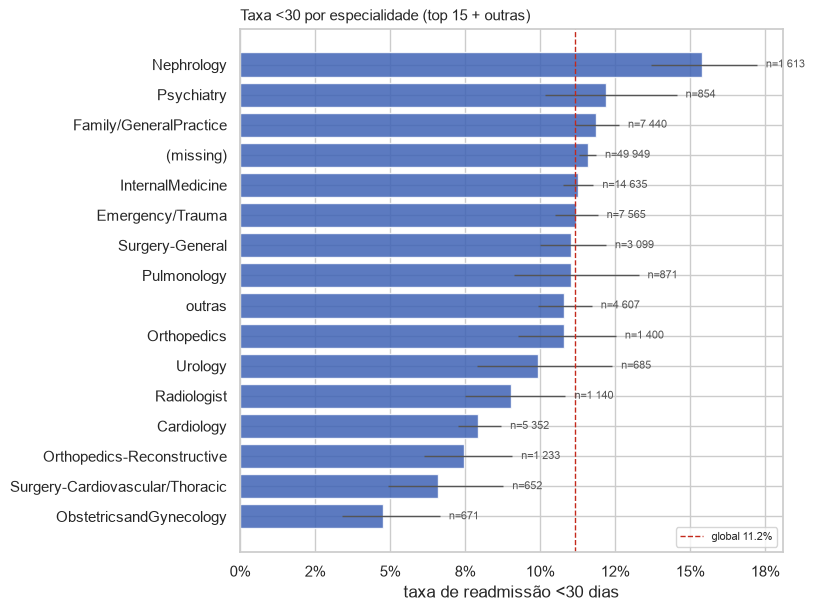

In [25]:
top_spec = spec.index[:15]
plot_rate(rate_by(df.assign(_s=df["medical_specialty"].fillna("(missing)").where(lambda s: s.isin(top_spec), "outras")), "_s")
          .sort_values("rate", ascending=False), "Taxa <30 por especialidade (top 15 + outras)")
plt.show()

Numéricas: taxa de `<30` por valor (cortado no percentil 99) e diferença de médias por classe.

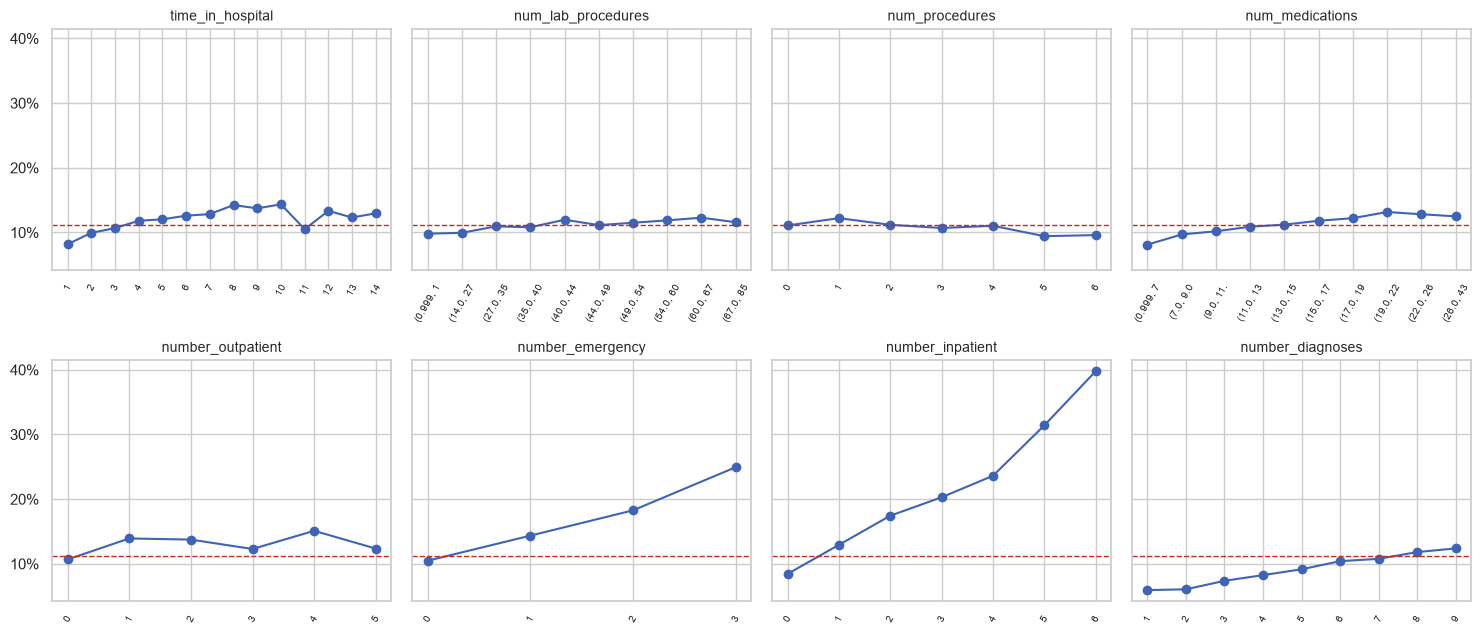

target,0,1,ratio
time_in_hospital,4.35,4.77,1.10
num_lab_procedures,42.95,44.23,1.03
num_procedures,1.35,1.28,0.95
num_medications,15.91,16.90,1.06
number_outpatient,0.36,0.44,1.22
number_emergency,0.18,0.36,2.00
number_inpatient,0.56,1.22,2.18
number_diagnoses,7.39,7.69,1.04


In [26]:
fig, axes = plt.subplots(2, 4, figsize=(15, 6.5), sharey=True)
for ax, c in zip(axes.flat, NUM_COLS):
    cap = int(df[c].quantile(0.99))
    x = df[c].clip(upper=cap)
    if x.nunique() > 15:
        x = pd.qcut(x, 10, duplicates="drop")
    g = df.assign(_x=x).groupby("_x", observed=True)["target"].agg(["mean", "size"]).sort_index()
    ax.plot(range(len(g)), g["mean"], marker="o", color="#3F63B5")
    ax.axhline(BASE_RATE, color="#C4291C", ls="--", lw=1)
    ax.set_xticks(range(len(g)), [str(i)[:9] for i in g.index], rotation=60, fontsize=7)
    ax.set_title(c, fontsize=10)
    ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1, decimals=0))
plt.tight_layout(); plt.show()
df.groupby("target")[NUM_COLS].mean().T.round(2).assign(ratio=lambda d: (d[1] / d[0]).round(2))

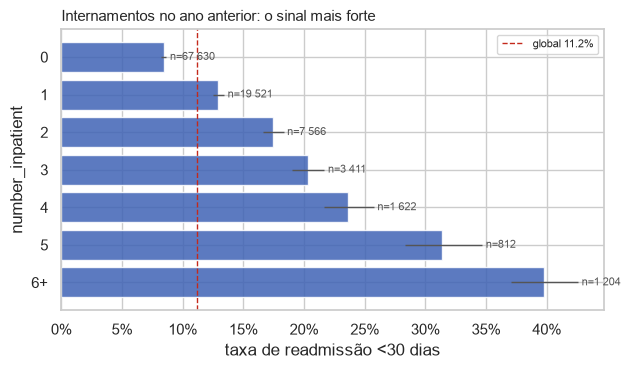

In [27]:
g = rate_by(df.assign(_i=df["number_inpatient"].clip(upper=6).astype(str).replace("6", "6+")), "_i",
            order=["0", "1", "2", "3", "4", "5", "6+"])
ax = plot_rate(g, "Internamentos no ano anterior: o sinal mais forte")
ax.set_ylabel("number_inpatient")
ax.figure.savefig(FIG_DIR / "05_taxa_number_inpatient.png", dpi=150, bbox_inches="tight"); plt.show()

**Conclusão.** O sinal mais forte é `number_inpatient`: 8,4% sem internamentos prévios, 12,9% com 1, 20,3% com 3 e 39,8% com 6 ou mais. `number_emergency` também duplica a média nos positivos. Destino da alta e `insulin` (Down 13,9%, Up 13,0% vs No 10,0%) diferenciam bem. Idade tem efeito pequeno a partir dos 20 anos (9,7%–14,2%). `race` e `gender` quase não diferenciam (≤1,7 p.p. nas categorias grandes), o que é bom para fairness mas sugere pouco valor preditivo. As restantes numéricas (`time_in_hospital`, `num_medications`, `number_diagnoses`) têm efeito pequeno (rácio de médias 1,04–1,10).

## 8. Diagnósticos (pré-T1.8)

diag_1: 716 códigos | V: 1.6% | E: 0.0%
diag_2: 748 códigos | V: 1.8% | E: 0.7%
diag_3: 789 códigos | V: 3.8% | E: 1.2%


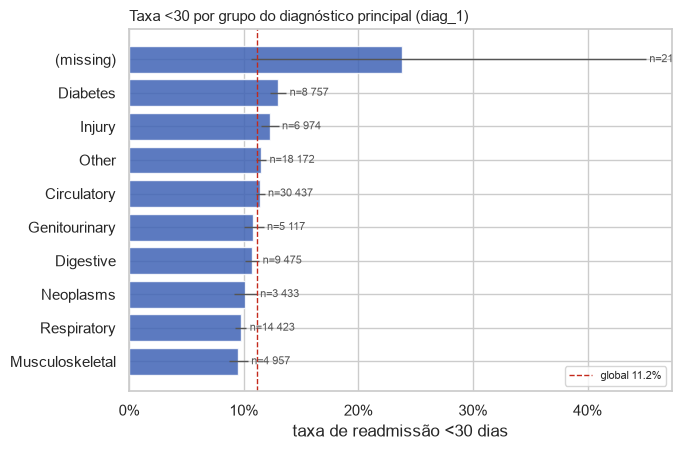

In [28]:
def icd9_group(code):
    """Grupos de Strack et al. (2014). Só para inspeção; as features constroem-se em T1.8."""
    if pd.isna(code):
        return "(missing)"
    if code.startswith(("V", "E")):
        return "Other"
    v = float(code)
    if 390 <= v <= 459 or int(v) == 785: return "Circulatory"
    if 460 <= v <= 519 or int(v) == 786: return "Respiratory"
    if 520 <= v <= 579 or int(v) == 787: return "Digestive"
    if int(v) == 250: return "Diabetes"
    if 800 <= v <= 999: return "Injury"
    if 710 <= v <= 739: return "Musculoskeletal"
    if 580 <= v <= 629 or int(v) == 788: return "Genitourinary"
    if 140 <= v <= 239: return "Neoplasms"
    return "Other"

for c in ["diag_1", "diag_2", "diag_3"]:
    s = df[c].dropna()
    print(f"{c}: {s.nunique()} códigos | V: {s.str.startswith('V').mean():.1%} | E: {s.str.startswith('E').mean():.1%}")
df["_diag1_grp"] = df["diag_1"].map(icd9_group)
plot_rate(rate_by(df, "_diag1_grp").sort_values("rate", ascending=False), "Taxa <30 por grupo do diagnóstico principal (diag_1)")
plt.show()

In [29]:
rate_by(df, "diag_1").query("n >= 500").sort_values("rate", ascending=False).head(10)[["n", "rate"]].round(3)

,n,rate
diag_1,,
250.7,871,0.189
250.6,1183,0.185
434,2028,0.162
440,840,0.158
820,1082,0.158
403,513,0.154
507,610,0.148
428,6862,0.141
250.11,625,0.141


**Conclusão.** Cada coluna de diagnóstico tem 716–789 códigos ICD-9, impraticáveis como categorias: agrupar (Strack et al.) em T1.8. Códigos V/E são poucos (até 5% em `diag_3`). Alguns códigos específicos têm taxas altas (ex.: complicações da diabetes 250.6/250.7 ≈ 19%, AVC 434 16%), por isso vale a pena manter uma flag de diabetes com complicações além do grupo.

## 9. Correlações e redundância

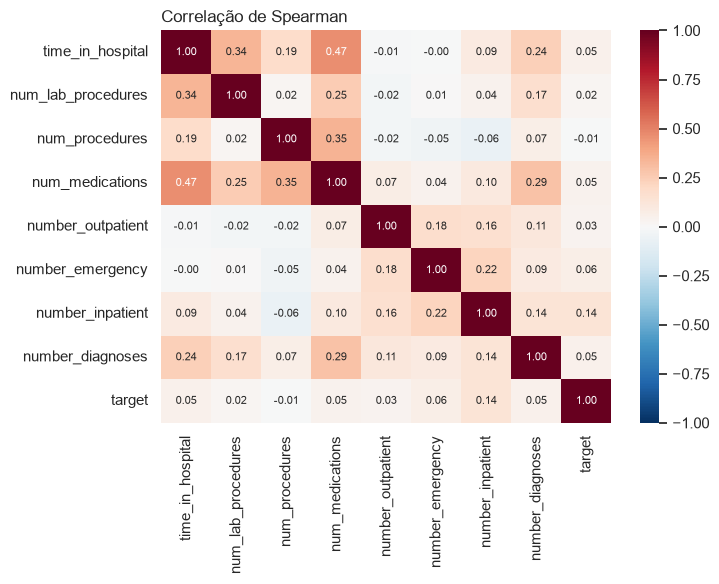

In [30]:
corr = df[NUM_COLS + ["target"]].corr(method="spearman")
fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax, annot_kws={"size": 8})
ax.set_title("Correlação de Spearman", loc="left"); plt.tight_layout(); plt.show()

In [31]:
def cramers_v(x, y):
    t = pd.crosstab(x, y)
    chi2 = chi2_contingency(t, correction=False)[0]
    n = t.values.sum()
    r, k = t.shape
    return np.sqrt(chi2 / (n * (min(r, k) - 1)))

assoc_cols = ["age", "race", "gender", "admission_type_id_desc", "discharge_disposition_id_desc",
              "admission_source_id_desc", "medical_specialty", "payer_code", "A1Cresult", "max_glu_serum",
              "insulin", "change", "diabetesMed", "_diag1_grp"]
v = pd.Series({c: cramers_v(df[c].fillna("(missing)"), df["target"]) for c in assoc_cols}).sort_values(ascending=False)
v.round(3).to_frame("V de Cramér com o target")

,V de Cramér com o target
discharge_disposition_id_desc,0.125
medical_specialty,0.058
insulin,0.043
age,0.034
payer_code,0.031
_diag1_grp,0.031
diabetesMed,0.027
admission_source_id_desc,0.023
change,0.020
A1Cresult,0.019


In [32]:
print("change vs diabetesMed:", round(cramers_v(df["change"], df["diabetesMed"]), 3))
print("admission_type vs admission_source:", round(cramers_v(df["admission_type_id_desc"].fillna("?"), df["admission_source_id_desc"].fillna("?")), 3))

change vs diabetesMed: 0.506
admission_type vs admission_source: 0.41


**Conclusão.** Não há numéricas redundantes: a maior correlação de Spearman é `num_medications` vs `time_in_hospital` (0,47), longe de 0,9. Em categóricas, `change` e `diabetesMed` estão associadas (V=0,51) e `admission_type` vs `admission_source` (V=0,41); não são redundantes ao ponto de descartar. Associação com o target: o destino da alta lidera (V=0,13, em parte por causa dos óbitos), seguido de `medical_specialty`, `insulin` e `age`; `gender` é praticamente nula (0,003).

## 10. Disponibilidade na alta (input para T1.6)

Para cada variável: é conhecida **no momento da alta**? O dataset é um extrato por encontro, por isso quase tudo é registado até à alta. Pontos a validar em T1.6:

| Variável | Questão |
|---|---|
| `readmitted` | É o resultado. **Nunca** é feature. |
| `discharge_disposition_id` | Conhecida na alta (é a própria decisão de alta). OK, mas usada também para definir a população (T1.4). |
| `number_outpatient/emergency/inpatient` | Contam visitas no **ano anterior** ao encontro. OK. |
| `diag_1–3` | Codificação ICD-9 pode ser finalizada depois da alta (faturação). Assumir disponível, mas registar o pressuposto. |
| `A1Cresult`, `max_glu_serum` | Resultado pode chegar já perto ou depois da alta. Assumir disponível. |
| Medicamentos / `change` / `diabetesMed` | Estado à alta. OK. |
| Contagens derivadas de `patient_nbr` (encontros no dataset) | **Risco de fuga**: contar encontros futuros do mesmo doente usa informação que não existe na alta. Só contagens de encontros **anteriores** seriam válidas, e o dataset não tem datas. |

**Conclusão.** Nenhuma variável original é claramente posterior à alta, exceto o próprio `readmitted`. O risco real está nas features **derivadas**: o nº de encontros do doente no dataset (secção 4) usa encontros futuros. Os pressupostos sobre `diag_*` e A1C/glucose devem ficar escritos em T1.6.

## 11. Conclusões e decisões a tomar

| Achado | Implicação | Tarefa |
|---|---|---|
| 11,16% de positivos | Métricas PR-AUC / recall@k; tratar desequilíbrio | T3.1, T3.2 |
| 46% dos encontros são de doentes recorrentes | Split agrupado por `patient_nbr` | T1.7 |
| Nº de encontros no dataset prevê o target por fuga | Proibir como feature | T1.6 |
| 2 423 encontros de óbito/hospício (43 positivos) | Excluir da população | T1.4 |
| `weight` 96,9% missing, sem sinal | Descartar | T1.9 |
| `examide`, `citoglipton` constantes; 13 medicamentos ≥99,3% `No` | Descartar; agregar em nº de medicamentos alterados | T1.8, T1.9 |
| "None" em A1C/glucose = não medido, com sinal | Manter como categoria | T1.8 |
| `medical_specialty` 49% missing, 73 níveis | `?` como categoria + agrupar raros | T1.9 |
| `payer_code` 40% missing, sinal fraco | Candidata a descartar; testar no modelo | T1.9, T2 |
| `number_inpatient` é o preditor mais forte | Incluir; considerar log1p/truncagem | T1.8 |
| Contagens de visitas muito assimétricas | log1p ou truncar no p99 | T1.8 |
| Diagnósticos com 700+ códigos | Agrupar em grupos ICD-9 + flag de complicações | T1.8 |
| "NULL"/"Not Available"/"Not Mapped" nos IDs | Tratar como desconhecido | T1.9 |
| `race`/`gender` com pouco sinal | Manter para fairness; decidir em equipa se entram no modelo | T3.5 |
| `gender` Unknown/Invalid (3) | Não reportar em fairness | T3.5 |

In [33]:
df = df.drop(columns=[c for c in df.columns if c.startswith("_")])  # limpar colunas auxiliares